# 05e · Feature-group ablation for the tree models

**Objective.** Show *which families of engineered features carry the forecast skill*, instead of only listing them. Feature groups are added cumulatively, from the raw recent history to the road-graph neighbour features, and each stage is scored on the **validation** period at a short (15 min) and a long (60 min) horizon.

| stage | adds | idea behind it |
|---|---|---|
| 1 | the 12 lagged speeds, the last observed value and its age | everything a purely autoregressive model sees |
| 2 | rolling means / standard deviations, trend, observed count | smoothed level and volatility of the recent past |
| 3 | cyclic time of day and day of week of the forecast target, weekend flag | recurrent demand pattern (rush hours) |
| 4 | sensor identity: training mean speed, latitude, longitude, categorical id | sensor-specific level and location |
| 5 | upstream / downstream neighbour speeds (road graph) | congestion propagating along the network |

**Reading the result.** Each stage is fitted once with a fixed seed on a thinned training set with the default hyper-parameters and a reduced round budget, so absolute errors are a little higher than in notebook 05. To judge which differences are real, the full model (stage 5) is repeated with two other random seeds; gains smaller than that spread should not be interpreted. All numbers are validation numbers; nothing here touches the test period.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, tabular as tb, tuning as tn, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
RETRAIN = False
ABL_HORIZONS = (3, 12)
td = tb.build_tabular(ctx, lat, lon, adjacency=graph.adjacency, splits=("train", "val_fit"))
thin = np.arange(0, len(td.origin_sets["train"]), config.TUNE_TRAIN_THIN)
rows_thin = tn.rows_for_origins(thin, N)
sample = td.design("train", 3, with_neighbours=True)
ALL = list(sample.columns); del sample
GROUPS = {
    "1 lags + last value": [c for c in ALL if c.startswith("lag_")] + ["last_observed", "age_last_observed"],
    "2 + rolling stats, trend": [c for c in ALL if c.startswith(("roll_", "trend_", "n_observed"))],
    "3 + calendar (target time)": [c for c in ALL if c.startswith("target_")],
    "4 + sensor identity": ["sensor_train_mean", "latitude", "longitude", "sensor_id"],
    "5 + road-graph neighbours": [c for c in ALL if c.startswith(("up_", "down_"))],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(ALL), "every column must belong to exactly one group"
for g, cols in GROUPS.items():
    print(f"{g:28s} {len(cols):2d} columns: {cols if len(cols) <= 6 else cols[:3] + ['...'] + cols[-2:]}")

1 lags + last value          14 columns: ['lag_0', 'lag_1', 'lag_2', '...', 'last_observed', 'age_last_observed']
2 + rolling stats, trend      7 columns: ['roll_mean_3', 'roll_mean_6', 'roll_mean_12', '...', 'n_observed_window', 'trend_3']
3 + calendar (target time)    5 columns: ['target_tod_sin', 'target_tod_cos', 'target_dow_sin', 'target_dow_cos', 'target_is_weekend']
4 + sensor identity           4 columns: ['sensor_train_mean', 'latitude', 'longitude', 'sensor_id']
5 + road-graph neighbours     8 columns: ['up_mean_lag0', 'up_min_lag0', 'up_n_observed', '...', 'down_n_observed', 'down_mean_lag3']


## 1 · Fit every stage at both horizons

In [3]:
out_path = config.METRICS_DIR / f"{config.tagged('feature_ablation')}.json"
done = json.loads(out_path.read_text()) if (not RETRAIN and out_path.is_file()) else {}
default_cfg = tn.default_candidate()
stages = list(GROUPS)
for h in ABL_HORIZONS:
    X_t, (r_t, ok_t, _) = td.design("train", h, with_neighbours=True).iloc[rows_thin], td.targets("train", h)
    r_t, ok_t = r_t[rows_thin], ok_t[rows_thin]
    X_v, (r_v, ok_v, _) = td.design("val_fit", h, with_neighbours=True), td.targets("val_fit", h)
    done.setdefault(f"h{h}_persistence", float(np.abs(r_v[ok_v]).mean()))
    for k, stage in enumerate(stages):
        key = f"h{h}_{stage}"
        if key in done:
            continue
        cols = sum((GROUPS[s] for s in stages[:k + 1]), [])
        done[key] = tn.fit_and_score(X_t[cols][ok_t], r_t[ok_t], X_v[cols][ok_v], r_v[ok_v], default_cfg)["val_mae"]
        out_path.write_text(json.dumps(done)); print(f"h={h * 5:2d} min | {stage:28s} {len(cols):2d} cols | validation MAE {done[key]:.4f}")
    for seed in (1, 2):                                          # seed noise of the full model
        key = f"h{h}_noise_seed{seed}"
        if key not in done:
            done[key] = tn.fit_and_score(X_t[ALL][ok_t], r_t[ok_t], X_v[ALL][ok_v], r_v[ok_v], {**default_cfg, "random_state": seed})["val_mae"]
            out_path.write_text(json.dumps(done)); print(f"h={h * 5:2d} min | full model, seed {seed}: {done[key]:.4f}")
    del X_t, X_v

h=15 min | 1 lags + last value          14 cols | validation MAE 2.8193


h=15 min | 2 + rolling stats, trend     21 cols | validation MAE 2.8180


h=15 min | 3 + calendar (target time)   26 cols | validation MAE 2.7461


h=15 min | 4 + sensor identity          30 cols | validation MAE 2.6757


h=15 min | 5 + road-graph neighbours    38 cols | validation MAE 2.6043


h=15 min | full model, seed 1: 2.6040


... (4 outputs left out)

h=60 min | 4 + sensor identity          30 cols | validation MAE 3.5754


h=60 min | 5 + road-graph neighbours    38 cols | validation MAE 3.5138


h=60 min | full model, seed 1: 3.5078


h=60 min | full model, seed 2: 3.5059


## 2 · Results

validation MAE (mph)         \
horizon_min                                  15     60   
stage                                                    
1 lags + last value                       2.819  4.382   
2 + rolling stats, trend                  2.818  4.381   
3 + calendar (target time)                2.746  3.984   
4 + sensor identity                       2.676  3.575   
5 + road-graph neighbours                 2.604  3.514   

                           gain vs previous stage (%)          
horizon_min                                        15      60  
stage                                                          
1 lags + last value                            12.719   9.288  
2 + rolling stats, trend                        0.046   0.020  
3 + calendar (target time)                      2.549   9.072  
4 + sensor identity                             2.564  10.253  
5 + road-graph neighbours                       2.670   1.725

seed-to-seed standard deviation of the full model (mph): {'15 min': 0.001, '60 min': 0.0041}


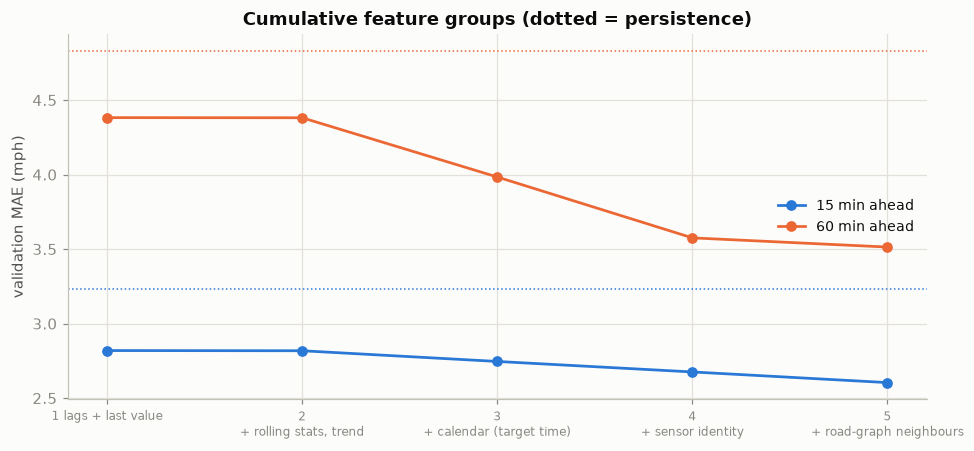

In [4]:
rows = []
for h in ABL_HORIZONS:
    prev = done[f"h{h}_persistence"]
    for stage in stages:
        v = done[f"h{h}_{stage}"]
        rows.append({"horizon_min": h * 5, "stage": stage, "validation MAE (mph)": v, "gain vs previous stage (%)": 100 * (prev - v) / prev,
                     "gain vs persistence (%)": 100 * (done[f"h{h}_persistence"] - v) / done[f"h{h}_persistence"]})
        prev = v
res = pd.DataFrame(rows)
res.to_csv(config.METRICS_DIR / f"{config.tagged('feature_ablation')}.csv", index=False)
display(res.pivot(index="stage", columns="horizon_min", values=["validation MAE (mph)", "gain vs previous stage (%)"]).round(3).loc[stages])
noise = {h: float(np.std([done[f"h{h}_{stages[-1]}"], done[f"h{h}_noise_seed1"], done[f"h{h}_noise_seed2"]], ddof=1)) for h in ABL_HORIZONS}
print("seed-to-seed standard deviation of the full model (mph):", {f"{h * 5} min": round(v, 4) for h, v in noise.items()})
fig, ax = plt.subplots(figsize=(9, 4.2))
for h, c in zip(ABL_HORIZONS, ("#2a78d6", "#eb6834")):
    s = res[res.horizon_min == h * 5]
    ax.plot(range(len(stages)), s["validation MAE (mph)"], marker="o", color=c, label=f"{h * 5} min ahead")
    ax.axhline(done[f"h{h}_persistence"], color=c, ls=":", lw=1)
ax.set_xticks(range(len(stages))); ax.set_xticklabels([s.replace(" + ", "\n+ ", 1) if s[0] != "1" else s for s in stages], fontsize=8)
ax.set_ylabel("validation MAE (mph)"); ax.set_title("Cumulative feature groups (dotted = persistence)"); ax.legend()
fig.tight_layout(); viz.save_figure(fig, "05e_feature_ablation"); plt.show()